# Intraday Volume Lab

### A reproducible Python research portfolio

**Portfolio edition maintained and improved by Bikash Kushwaha**

This notebook forecasts the next minute's trading volume using recent price, volume, and order-book features. It combines a convolutional encoder, a context branch, and instrument embeddings.

**The demonstration uses synthetic data and fictional symbols.** It demonstrates the workflow and its checks; it is not evidence of real-market forecasting performance. The model is compared with the simple baseline of repeating the last observed minute's volume.


## 1. Experiment configuration

The target is interval volume in shares. A 15-minute history predicts the immediately following minute. A fixed seed, explicit timezone, file hashes, and whole-date evaluation boundaries make the assumptions inspectable.


In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from volume_lab import chronological_split, load_ticks, make_samples, minute_bars, train_experiment

ROOT = Path.cwd()
if not (ROOT / "volume_lab.py").is_file():
    raise RuntimeError("Start this notebook from the project root.")
DATA = ROOT / "data" / "sample"
ARTIFACTS = ROOT / "artifacts" / "demo"
DATA_LABEL = "Synthetic demonstration · fictional symbols"
LOOKBACK = 15
EPOCHS = 5
SEED = 42

display(
    pd.DataFrame(
        {
            "Setting": ["Data", "Target", "Lookback", "Exchange timezone", "Epochs", "Seed"],
            "Value": [
                DATA_LABEL,
                "Next-minute interval volume (shares)",
                "15 preceding complete minutes",
                "Asia/Kolkata",
                EPOCHS,
                SEED,
            ],
        }
    )
)

,Setting,Value
0,Data,Synthetic demonstration · fictional symbols
1,Target,Next-minute interval volume (shares)
2,Lookback,15 preceding complete minutes
3,Exchange timezone,Asia/Kolkata
4,Epochs,5
5,Seed,42


## 2. Validate ticks and recover interval volume

The bundled sample contains two fictional instruments over eight short sessions. It uses numeric epoch seconds and a cumulative volume counter that resets daily. The loader combines files, removes exact duplicate records, and rejects invalid input.

Volume is computed from counter increments within each instrument/session. An unknown initial counter makes the first minute partial, so that minute is discarded. A counter decrease within a session is an error. Missing minutes are not filled.


In [2]:
ticks = load_ticks(DATA, timestamp_unit="s", exchange_timezone="Asia/Kolkata")
bars = minute_bars(ticks)
display(
    pd.DataFrame(
        {
            "Input": ["Tick records", "Complete minute bars", "Symbols", "Local session dates"],
            "Count": [
                len(ticks),
                len(bars),
                bars["symbol"].nunique(),
                bars["timestamp"].dt.date.nunique(),
            ],
        }
    )
)
display(bars[["timestamp", "symbol", "close", "volume", "spread", "imbalance"]].head(6))

,Input,Count
0,Tick records,1936
1,Complete minute bars,960
2,Symbols,2
3,Local session dates,8


,timestamp,symbol,close,volume,spread,imbalance
0,2026-01-05 09:15:00+05:30,ALPHA,99.9946,1135.0,0.04,-0.099132
1,2026-01-05 09:15:00+05:30,BETA,179.9993,2072.0,0.04,0.121855
2,2026-01-05 09:16:00+05:30,ALPHA,100.0075,1011.0,0.04,-0.092667
3,2026-01-05 09:16:00+05:30,BETA,180.0114,1737.0,0.04,-0.035709
4,2026-01-05 09:17:00+05:30,ALPHA,100.0115,1012.0,0.04,-0.115806
5,2026-01-05 09:17:00+05:30,BETA,180.0569,1856.0,0.04,0.058627


## 3. Causal features and chronological validation

Each window uses five sequential features and six aggregate context features from completed bars. Windows cannot cross a gap or a session boundary. All instruments share the same date cutoffs. Scalers and the instrument vocabulary fit the training partition only.

The eight-date example assigns five dates to training, one to validation, and two to testing. Shuffling is allowed only after the training partition has been selected.


In [3]:
samples = make_samples(bars, lookback=LOOKBACK)
splits = chronological_split(samples)
partition_table = pd.DataFrame(
    [
        {
            "Partition": name.title(),
            "Samples": len(part.target),
            "First target": part.metadata["timestamp"].min().isoformat(),
            "Last target": part.metadata["timestamp"].max().isoformat(),
            "Session dates": part.metadata["timestamp"].dt.date.nunique(),
        }
        for name, part in splits.items()
    ]
)
display(partition_table)
print(f"Sequential tensor: {samples.high.shape}; context tensor: {samples.context.shape}")
assert (samples.metadata["feature_end"] < samples.metadata["timestamp"]).all()
assert (
    splits["train"].metadata["timestamp"].max() < splits["validation"].metadata["timestamp"].min()
)
assert splits["validation"].metadata["timestamp"].max() < splits["test"].metadata["timestamp"].min()
print("Causality and partition-boundary checks passed.")

,Partition,Samples,First target,Last target,Session dates
0,Train,450,2026-01-05T09:30:00+05:30,2026-01-09T10:14:00+05:30,5
1,Validation,90,2026-01-12T09:30:00+05:30,2026-01-12T10:14:00+05:30,1
2,Test,180,2026-01-13T09:30:00+05:30,2026-01-14T10:14:00+05:30,2


Sequential tensor: (720, 15, 5); context tensor: (720, 6)
Causality and partition-boundary checks passed.


## 4. Three-branch neural regressor

The sequential branch has Conv1D layers with 64 and 32 filters, layer normalization, and flattening. A 32-unit dense branch encodes the context. An 8-dimensional embedding represents each instrument. Their concatenation feeds 128- and 64-unit dense layers with dropout and L2 regularization.

Training uses Adam, mean squared error on standardized log-volume, early stopping, learning-rate reduction, and best-model checkpointing. This direct regressor does not implement CMEM residual estimation.


In [4]:
result = train_experiment(
    samples,
    ARTIFACTS,
    epochs=EPOCHS,
    seed=SEED,
    data_label=DATA_LABEL,
    input_manifest=ticks.attrs["input_manifest"],
)
display(
    pd.DataFrame(
        [{"Library": name, "Version": version} for name, version in result["versions"].items()]
    )
)
print(f"Completed {result['epochs_completed']} epochs. Model and preprocessing saved locally.")
display(
    {
        "application/vnd.intraday-volume-lab.run+json": {"run_id": result["run_id"]},
        "text/plain": f"Run reference: {result['run_id']}",
    },
    raw=True,
)

,Library,Version
0,python,3.12.14
1,tensorflow,2.20.0
2,keras,3.15.1
3,numpy,2.3.5
4,pandas,3.0.1
5,scikit-learn,1.9.1
6,matplotlib,3.11.2


Completed 5 epochs. Model and preprocessing saved locally.


Run reference: e6d8efd4da9249249b41685cc62209ed

## 5. Compare against persistence

The table reports errors in **original share units**. The persistence baseline predicts the last observed minute's volume. It is a demanding reference for this smooth synthetic series; a neural model need not beat it, especially after a short demonstration run.

The results JSON also reports log-volume metrics separately. No archived research scores are substituted for the run below.


In [5]:
rows = []
for partition, models in result["metrics"].items():
    for model_name, metrics in models.items():
        rows.append(
            {
                "Partition": partition.title(),
                "Predictor": model_name.title(),
                "MAE (shares)": metrics["shares"]["mae"],
                "RMSE (shares)": metrics["shares"]["rmse"],
                "R²": metrics["shares"]["r2"],
                "SMAPE (%)": metrics["shares"]["smape_pct"],
            }
        )
metric_table = pd.DataFrame(rows)
display(metric_table.round(3))
test_metrics = result["metrics"]["test"]
model_mae = test_metrics["model"]["shares"]["mae"]
baseline_mae = test_metrics["persistence"]["shares"]["mae"]
print(f"Held-out MAE: model {model_mae:.2f} shares; persistence {baseline_mae:.2f} shares.")
print("Synthetic-data workflow check only; no real-market performance claim.")

,Partition,Predictor,MAE (shares),RMSE (shares),R²,SMAPE (%)
0,Train,Model,110.598,148.950,0.845,10.975
1,Train,Persistence,89.747,120.614,0.898,8.816
2,Validation,Model,170.716,223.673,0.651,16.300
3,Validation,Persistence,102.111,138.244,0.867,9.292
4,Test,Model,165.189,220.777,0.619,16.857
5,Test,Persistence,94.789,128.840,0.870,9.155


Held-out MAE: model 165.19 shares; persistence 94.79 shares.
Synthetic-data workflow check only; no real-market performance claim.


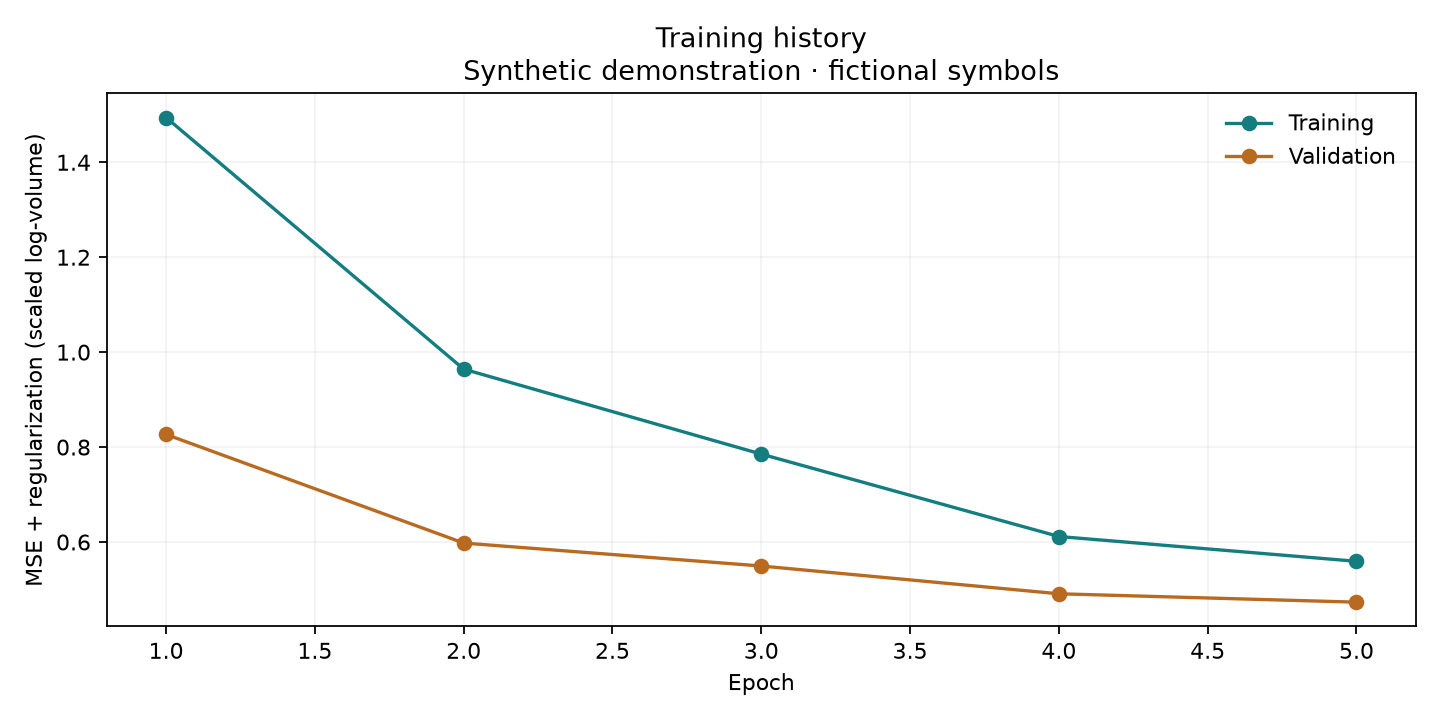

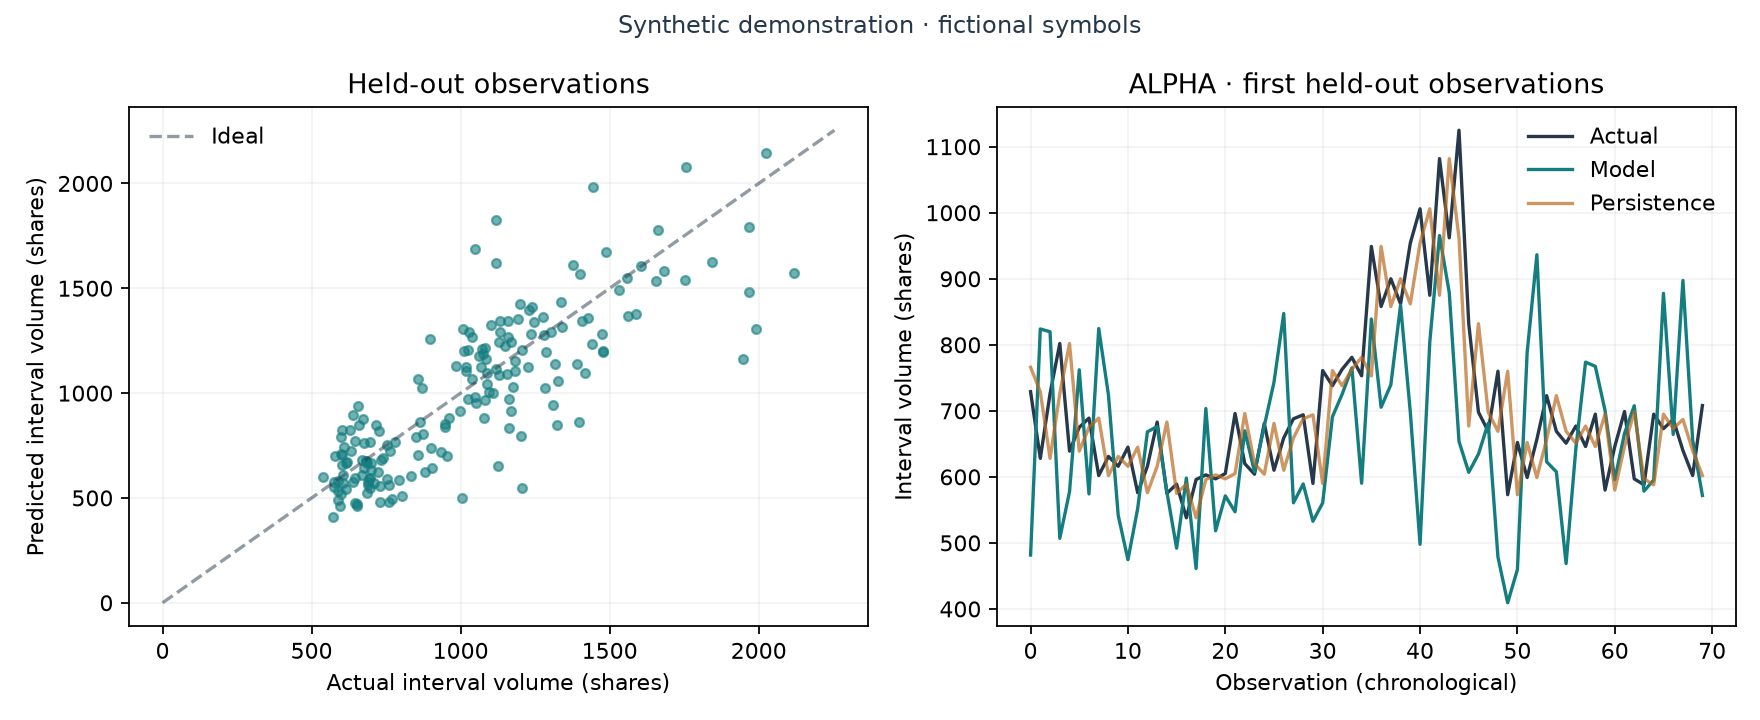

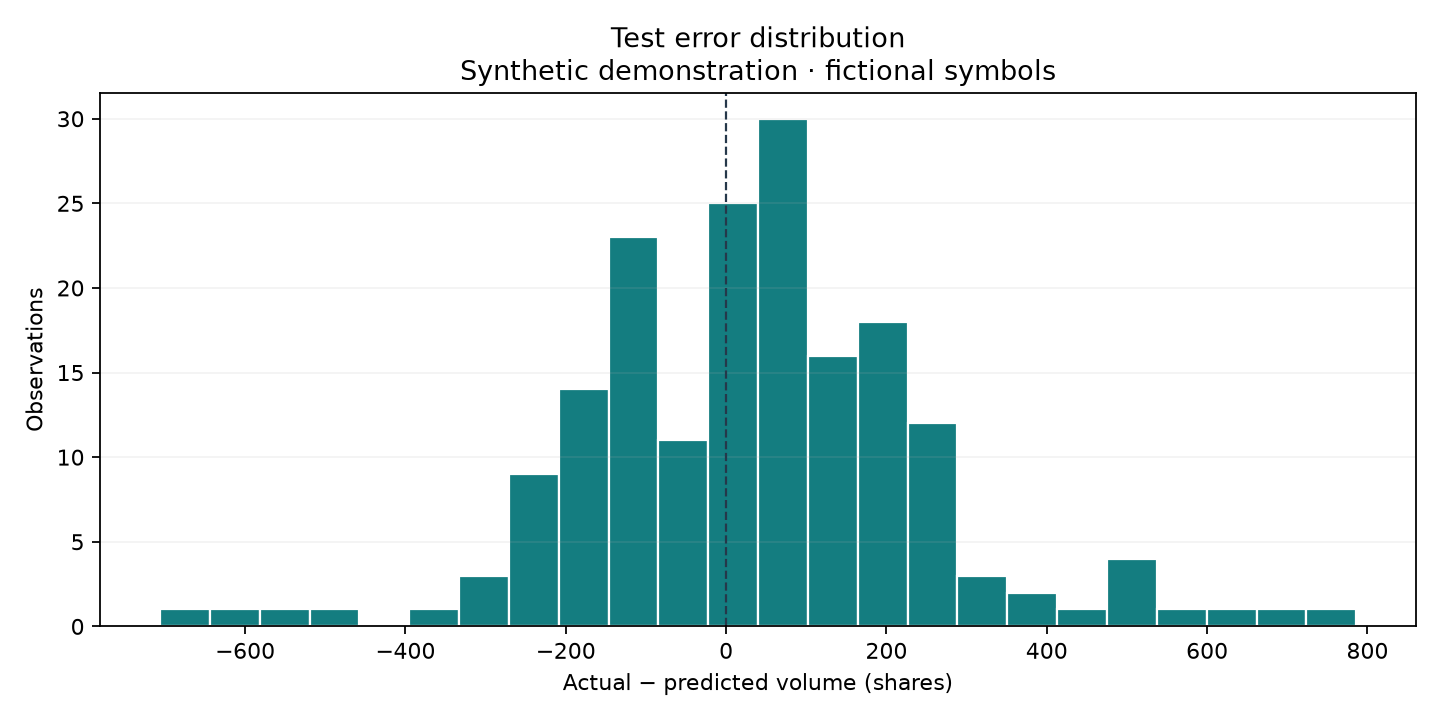

In [6]:
for filename in ("learning-curve.png", "predictions.png", "error-distribution.png"):
    display(Image(filename=str(ARTIFACTS / "figures" / filename)))

## 6. Reproducibility and limitations

The maintained edition includes regression checks for interval-volume arithmetic, partial minutes, daily resets, duplicate files, timestamp units, missing bars, causal windows, common date boundaries, training-only scalers, finite metrics, and model persistence.

The sample data is deliberately small and synthetic. Evaluation does not establish market performance, execution gains, or live readiness. Calendar-date sessions suit this sample; overnight sessions or feed resets require a different session policy. Inputs remain in memory, so larger datasets need memory profiling and partitioning.

To reproduce this report, install the pinned development requirements, run the test suite, then execute this notebook from the project root. Its results file records the inputs' hashes, seed, library versions, date ranges, and metric units. Full real-data reproduction requires an authorized dataset that was not included in the supplied archive.


## Source acknowledgement

This portfolio edition is maintained and improved by **Bikash Kushwaha**. It consolidates the supplied research workflow into a reproducible, tested demonstration.

The architecture adapts the supplied notebook's CNN/context/embedding regressor. [DeepLOB](https://arxiv.org/abs/1808.03668) and [CMEM research](https://academic.oup.com/jfec/article-abstract/9/3/489/840918) provide scientific context. This edition does not claim a complete reproduction of either paper.
